In [1]:
import pandas as pd
import numpy as np
import os, time, warnings
import matplotlib.pyplot as plt
%matplotlib inline
warnings.filterwarnings('ignore')

## Данные соревнования МТС: https://ods.ai/competitions/competition-recsys-21/data

In [2]:
# !pip install pandas numpy scikit-learn implicit torch tqdm
# пакеты уже установлены в окружение ~/.venvs/recsys скриптом scripts/setup_and_download.sh
import sklearn, implicit, torch
print('implicit', implicit.__version__, '| torch', torch.__version__, '| sklearn', sklearn.__version__)

implicit 0.7.3 | torch 2.14.1 | sklearn 1.9.1


In [3]:
# аналог !wget 'https://storage.yandexcloud.net/datasouls-ods/materials/04adaecc/interactions.csv' — кладём в data/kion/
import urllib.request
DATA_PATH = os.path.join('data', 'kion', 'interactions.csv')
if not os.path.exists(DATA_PATH):
    os.makedirs(os.path.dirname(DATA_PATH), exist_ok=True)
    urllib.request.urlretrieve('https://storage.yandexcloud.net/datasouls-ods/materials/04adaecc/interactions.csv', DATA_PATH)
print(DATA_PATH, os.path.getsize(DATA_PATH) // 2**20, 'MB')

data/kion/interactions.csv 171 MB


In [4]:
df = pd.read_csv(DATA_PATH)
df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


In [5]:
df["last_watch_dt"] = pd.to_datetime(df["last_watch_dt"]) - pd.to_datetime(df["last_watch_dt"]).min()
df["last_watch_dt"] = df.last_watch_dt.apply(lambda x: int(str(x).split()[0]))
df.sample(5)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
53043,126778,5021,158,2202,37.0
4244261,779404,1166,60,33407,100.0
1304876,653939,3783,78,41123,50.0
593887,99334,12828,62,8194,100.0
4169384,1024226,12995,90,9971,100.0


In [6]:
df.shape, df['user_id'].nunique(), df['item_id'].nunique()

((5476251, 5), 962179, 15706)

<Axes: >

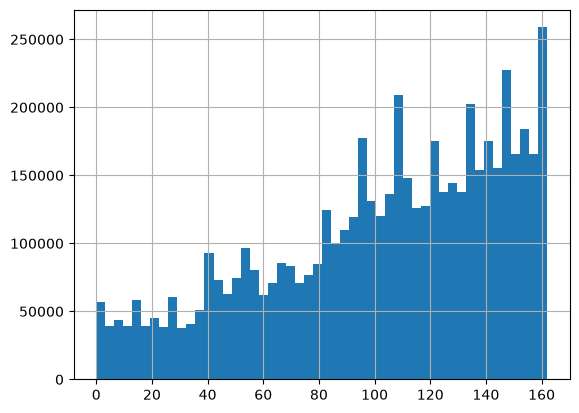

In [7]:
df['last_watch_dt'].hist(bins=50)

In [8]:
max_watch_dt = df['last_watch_dt'].max()
max_watch_dt

np.int64(162)

#### Разобьем датасет на трейн и тест. в тест отправим все события за последние 30 дней, в трейн все остальное. Посчитаем число уникальных юзеров в трейне и тесте, и юзеров, которые есть и там и там. Затем оставим в тесте только тех юзеров/айтемы, которые есть в трейне

In [9]:
# тест — последние 30 дней после дня max_watch_dt - 30 (граница включается в тест), трейн — всё, что раньше
test_start = max_watch_dt - 30
train_df = df[df['last_watch_dt'] < test_start].copy()
test_df = df[df['last_watch_dt'] >= test_start].copy()

train_users_all, test_users_all = train_df['user_id'].unique(), test_df['user_id'].unique()
print('Юзеров в трейне:', len(train_users_all), '| в тесте:', len(test_users_all),
      '| и там, и там:', len(np.intersect1d(train_users_all, test_users_all)))

assert train_df.shape[0] == 3740952
assert test_df.shape[0] == 1735299

Юзеров в трейне: 720875 | в тесте: 434353 | и там, и там: 193049


In [10]:
old_shape = test_df.shape[0]
test_df = test_df[test_df['user_id'].isin(train_df['user_id'].unique())
                  & test_df['item_id'].isin(train_df['item_id'].unique())].copy()

assert test_df.shape[0] == 851974
assert test_df['user_id'].nunique() == 186701
assert test_df['item_id'].nunique() == 8867


print(f"Размер тестовой выборки после фильтрации: {test_df.shape[0]} (было удалено {old_shape - test_df.shape[0]} строк или {100 * (old_shape - test_df.shape[0]) / old_shape:.2f}%)")
print(f"Число уникальных пользователей в тестовой выборке: {test_df.user_id.nunique()}")

Размер тестовой выборки после фильтрации: 851974 (было удалено 883325 строк или 50.90%)
Число уникальных пользователей в тестовой выборке: 186701


#### Насэмплируем 50_000 юзеров которые есть и в трейне и в тесте и ограничим тестовую и трейновую выборку только этими пользователями

In [11]:
np.random.seed(42)
train_users = train_df['user_id'].unique()
test_users = test_df.user_id.unique()
n_users = 50_000

both_users = np.intersect1d(train_users, test_users)
sampled_users = np.random.choice(both_users, size=n_users, replace=False)
train_df = train_df[train_df['user_id'].isin(sampled_users)].copy()
test_df = test_df[test_df['user_id'].isin(sampled_users)].copy()

assert train_df['last_watch_dt'].max() < test_df['last_watch_dt'].min()
assert train_df['user_id'].nunique() == n_users
assert test_df['user_id'].nunique() == n_users

In [12]:
train_items = train_df['item_id'].unique()
test_df = test_df[test_df['item_id'].isin(train_items)].copy()

In [13]:
print(train_df['user_id'].nunique(), train_df['item_id'].nunique())
print(test_df['user_id'].nunique(), test_df['item_id'].nunique())
print(train_df.shape, test_df.shape)

50000 9743
49959 6159
(481529, 5) (227262, 5)


In [14]:
def ndcg_metric(gt_items, predicted):
    at = len(predicted)
    relevance = np.array([1 if x in predicted else 0 for x in gt_items])
    # DCG uses the relevance of the recommended items
    rank_dcg = dcg(relevance)

    if rank_dcg == 0.0:
        return 0.0

    # IDCG has all relevances to 1 (or the values provided), up to the number of items in the test set that can fit in the list length
    ideal_dcg = dcg(np.sort(relevance)[::-1][:at])

    if ideal_dcg == 0.0:
        return 0.0

    ndcg_ = rank_dcg / ideal_dcg

    return ndcg_


def dcg(scores):
    return np.sum(
        np.divide(np.power(2, scores) - 1, np.log2(np.arange(scores.shape[0], dtype=np.float64) + 2)), dtype=np.float64
    )


def recall_metric(gt_items, predicted):

    n_gt = len(gt_items)
    intersection = len(set(gt_items).intersection(set(predicted)))
    return intersection / n_gt


def evaluate_recommender(df, model_preds, gt_col="test_interactions", topn=10):
    metric_values = []

    for idx, row in df.iterrows():
        gt_items = row[gt_col]
        metric_values.append((ndcg_metric(gt_items, row[model_preds]), recall_metric(gt_items, row[model_preds])))

    return {"ndcg": np.mean([x[0] for x in metric_values]), "recall": np.mean([x[1] for x in metric_values])}

In [15]:
# В шаблонной ndcg_metric релевантность считается по порядку gt_items, а не по позициям рекомендаций,
# поэтому она не зависит от порядка выдачи. Оставляем её для совместимости с шаблоном и добавляем
# стандартный NDCG@k по позициям рекомендованного списка.
def ndcg_at_k(gt_items, predicted, k=None):
    predicted = list(predicted)[:k] if k else list(predicted)
    gt = set(gt_items)
    rel = np.array([1.0 if x in gt else 0.0 for x in predicted])
    discounts = 1 / np.log2(np.arange(2, len(predicted) + 2))
    idcg = discounts[:min(len(gt), len(predicted))].sum()
    return float((rel * discounts).sum() / idcg) if idcg > 0 else 0.0


def evaluate_full(df, model_preds, gt_col="test_interactions", ks=(10, 50)):
    res = evaluate_recommender(df, model_preds, gt_col)
    for k in ks:
        res[f'ndcg@{k}'] = np.mean([ndcg_at_k(g, p, k) for g, p in zip(df[gt_col], df[model_preds])])
        res[f'recall@{k}'] = np.mean([recall_metric(g, list(p)[:k]) for g, p in zip(df[gt_col], df[model_preds])])
    return res

results = {}   # сводная таблица всех моделей

In [16]:
test_df_grouped = test_df.groupby('user_id').apply(lambda x: list(x['item_id']), include_groups=False).reset_index(name='test_interactions')
test_df_grouped.head()

,user_id,test_interactions
0,3,"[12192, 9728, 16406, 15719, 10440, 3475, 2025,..."
1,53,"[1445, 4151, 12250, 15629, 3734, 16426, 15810,..."
2,98,"[4689, 512, 5051]"
3,106,"[14619, 12908, 10544, 13335, 6267, 13463, 5411..."
4,155,"[8101, 5077, 281, 9006]"


In [17]:
# Бейзлайн: популярное за последние 7 дней трейна (без уже просмотренного)
recent = train_df[train_df.last_watch_dt >= train_df.last_watch_dt.max() - 6]
pop_items = recent.item_id.value_counts().index.tolist()
seen_by_user = train_df.groupby('user_id')['item_id'].apply(set)
test_df_grouped['toppop_recs'] = [[i for i in pop_items[:200] if i not in seen_by_user[u]][:50] for u in test_df_grouped.user_id]
results['TopPopular (7 дней)'] = evaluate_full(test_df_grouped, 'toppop_recs')
results['TopPopular (7 дней)']

{'ndcg': np.float64(0.4719573235107175),
 'recall': np.float64(0.3350469448578611),
 'ndcg@10': np.float64(0.1662584059477492),
 'recall@10': np.float64(0.23852507285540714),
 'ndcg@50': np.float64(0.19204532206852876),
 'recall@50': np.float64(0.3350469448578611)}

### ALS

Итак, поставлена задача построения модели со скрытыми переменными (latent factor model) для коллаборативной фильтрации:

$$\sum_{u,i} (r_{ui} - \langle p_u, q_i \rangle)^2 \to \min_{P,Q}. $$

Напомним, что суммирование ведется по всем парам $(u, i),$ для которых известен рейтинг $r_{ui}$ (и только по ним), а $p_u, q_i$ – латентные представления пользователя $u$ и товара $i$ из соответствующих матрицы $P, Q$.

Подход ALS (Alternating Least Squares) решает задачу, попеременно фиксируя матрицы $P$ и $Q$, — оказывается, что, зафиксировав одну из матриц, можно выписать аналитическое решение задачи для другой.

$$\nabla_{p_u} \bigg[ \sum_{u,i} (r_{ui} - \langle p_u, q_i \rangle)^2 \bigg] = \sum_{i} 2(r_{ui} - \langle p_u, q_i \rangle)q_i = 0$$

Воспользовавшись тем, что $a^Tbc = cb^Ta$, получим
$$\sum_{i} r_{ui}q_i - \sum_i q_i q_i^T p_u = 0.$$
Тогда окончательно каждый столбец матрицы $P$ можно найти по формуле
$$p_u = \bigg( \sum_i q_i q_i^T\bigg)^{-1}\sum_ir_{ui}q_i \;\; \forall u,$$
аналогично для столбцов матрицы $Q$
$$q_i = \bigg( \sum_u p_u p_u^T\bigg)^{-1}\sum_ur_{ui}p_u \;\; \forall i.$$

Таким образом мы можем решать оптимизационную задачу, поочередно фиксируя одну из матриц $P$ или $Q$ и проводя оптимизацию по второй.

**Оригинальная статья (для explicit feedback):**

Bell, R.M. and Koren, Y., 2007, October. Scalable collaborative filtering with jointly derived neighborhood interpolation weights. In Seventh IEEE international conference on data mining (ICDM 2007) (pp. 43-52). IEEE.


### iALS


**Статья для implicit данных:**


Implicit feedback ALS:
* Hu, Y., Koren, Y. and Volinsky, C., 2008, December. Collaborative filtering for implicit feedback datasets. In 2008 Eighth IEEE international conference on data mining (pp. 263-272). Ieee. http://yifanhu.net/PUB/cf.pdf

**Особенности:**

1. Нет explicit данных (явных позитивных и отрицательных оценок). <br>
2. Много шума в данных.  <br>
3. Используются свои функции и метрики для оценки implicit feedback. Если в explicit $r_ui$ - это оценки предпочтений пользователя, то в implicit - это степень уверенности. <br>


| Критерий | ALS  |  iALS | 
|---|---|---|
| Тип данных | Этот подход используется, когда у вас есть явные рейтинги или оценки, предоставленные пользователями для различных предметов. Например, пользователи могут оценивать фильмы по шкале от 1 до 5. |  Этот подход используется, когда у вас есть неявные сигналы взаимодействия между пользователями и предметами, такие как клики, просмотры, покупки или временные интервалы между действиями. |  
|
|Цель | Модель стремится точно предсказать явные рейтинги или оценки, которые пользователи могли бы дать предметам. | Модель стремится моделировать уровень уверенности или важности взаимодействия между пользователем и предметом, но не предсказывает явные рейтинги.|  
|
|Функции потерь| Обычно использует функцию потерь, такую как среднеквадратичная ошибка (MSE), для минимизации разницы между предсказанными и фактическими оценками. | Использует функцию потерь, которая учитывает уверенность в неявных взаимодействиях и стремится увеличить уверенность для более важных взаимодействий.| 
|
|Взвешивание| Не уделяет внимания взаимодействиям, которые не были явно оценены пользователями. Исключает информацию о неявных действиях. | Дополнительная параметризация. Учитывает все неявные действия, но с учетом их уверенности или веса, что позволяет модели учесть важность различных видов взаимодействий| 
|

Библиотека implicit: https://benfred.github.io/implicit/

In [18]:
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix

class NaiveALS:
    """ALS для задачи sum_{u,i} (r_ui - <p_u, q_i>)^2 + reg * (||P||^2 + ||Q||^2) по всей матрице (нули = «не смотрел»).
    Матрицу интеракций храним в sparse-виде: в dense 50k x ~14k float64 это ~6 ГБ, а формулы шага от этого не меняются:
    p_u = (Q^T Q + reg I)^-1 Q^T r_u  ->  P = R Q (Q^T Q + reg I)^-1 — одно матричное умножение на sparse R."""

    def __init__(self, n_iters, n_factors, reg=0, random_state=42):
        self.reg = reg
        self.n_iters = n_iters
        self.n_factors = n_factors
        self.random_state = random_state
        self.history = []

    def fit(self, train: pd.DataFrame, test: pd.DataFrame = None):
        n_users = train["user_id"].nunique()
        m_items = train["item_id"].nunique()

        self.user_encoder = LabelEncoder()
        self.item_encoder = LabelEncoder()

        encoded_users = self.user_encoder.fit_transform(train["user_id"].values)
        encoded_item = self.item_encoder.fit_transform(train["item_id"].values)

        train_ratings = csr_matrix((np.ones(len(encoded_users)), (encoded_users, encoded_item)), shape=(n_users, m_items))
        train_ratings.data[:] = 1.0          # бинарная матрица (повторные просмотры не суммируем)
        self.train_ratings = train_ratings
        print(train_ratings.shape)

        rng = np.random.default_rng(self.random_state)
        self.P = rng.random((n_users, self.n_factors))
        self.Q = rng.random((m_items, self.n_factors))

        ratings_T = train_ratings.T.tocsr()
        for i in tqdm(range(self.n_iters)):
            self.P = self._als_step(train_ratings, self.P, self.Q)
            self.Q = self._als_step(ratings_T, self.Q, self.P)
            self.history.append(self._losses())
        return self

    def _als_step(self, ratings, solve_vecs, fixed_vecs):
        # solve_vecs - матрица которую мы оптимизируем(юзеры/айтемы)
        # fixed_vecs - матрица которая у нас в данный момент зафиксирована
        A = fixed_vecs.T @ fixed_vecs + self.reg * np.eye(self.n_factors)   # sum_i q_i q_i^T + reg I
        b = ratings @ fixed_vecs                                             # sum_i r_ui q_i для всех u сразу
        result = np.linalg.solve(A, b.T).T
        return result # [n_users / m_items, n_factors]

    def _losses(self):
        R = self.train_ratings
        rows, cols = R.nonzero()
        pred_observed = np.einsum('ij,ij->i', self.P[rows], self.Q[cols])
        mse_observed = float(np.mean((R.data - pred_observed) ** 2))   # MSE только по ненулевым (как compute_mse)
        # MSE по всей матрице без её материализации: ||R - PQ^T||^2 = ||R||^2 - 2 tr(P^T R Q) + tr(P^T P Q^T Q)
        full = (R.data ** 2).sum() - 2 * np.sum(self.P * (R @ self.Q)) + np.sum((self.P.T @ self.P) * (self.Q.T @ self.Q))
        return {'mse_observed': mse_observed, 'mse_full': float(full / (R.shape[0] * R.shape[1]))}

    def predict(self):
        pred = self.P.dot(self.Q.T)
        return pred

    def get_top_k_predicts(self, k: int, users=None, batch_size: int = 2000):
        # output pd.DataFrame
        # user_id, predict(list of item ids)
        users = self.user_encoder.classes_ if users is None else np.asarray(users)
        enc = self.user_encoder.transform(users)
        all_recs = []
        for start in range(0, len(enc), batch_size):
            batch = enc[start:start + batch_size]
            scores = self.P[batch] @ self.Q.T
            seen = self.train_ratings[batch].nonzero()
            scores[seen] = -np.inf
            top = np.argpartition(-scores, k, axis=1)[:, :k]
            top = np.take_along_axis(top, np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1), axis=1)
            all_recs.extend(self.item_encoder.inverse_transform(top.ravel()).reshape(top.shape).tolist())
        df_pred = pd.DataFrame({'user_id': users, 'naive_als_pred': all_recs})
        return df_pred


    @staticmethod
    def compute_mse(y_true, y_pred):
        mask = np.nonzero(y_true)
        mse = mean_squared_error(y_true[mask], y_pred[mask])
        return mse

In [19]:
naive_als = NaiveALS(n_iters=10, n_factors=16, reg=0.01)
naive_als.fit(train_df, test_df)
pd.DataFrame(naive_als.history).rename_axis('iteration')

(50000, 9743)


  0%|          | 0/10 [00:00<?, ?it/s]

,mse_observed,mse_full
iteration,,
0,0.869080,0.000902
1,0.754177,0.000791
2,0.746655,0.000778
3,0.745674,0.000775
4,0.745457,0.000773
5,0.745349,0.000773
6,0.745284,0.000772
7,0.745239,0.000772
8,0.745196,0.000772


In [20]:
# предсказания строим в том же порядке пользователей, что и в test_df_grouped
preds = naive_als.get_top_k_predicts(k=50, users=test_df_grouped.user_id.values)
test_df_grouped["als_recs_naive"] = preds['naive_als_pred']
results['NaiveALS (16 факторов)'] = evaluate_full(test_df_grouped, "als_recs_naive")
evaluate_recommender(test_df_grouped, model_preds="als_recs_naive")

{'ndcg': np.float64(0.3243943549346698),
 'recall': np.float64(0.2076561848592076)}

In [21]:
from typing import List

from scipy.sparse import csr_matrix
from implicit.als import AlternatingLeastSquares
from implicit.bpr import BayesianPersonalizedRanking

from sklearn.metrics import mean_squared_error


class ImplicitModel:
    def __init__(self, model):
        self.model = model
        self.trained = False

    def fit(self, train_df: pd.DataFrame):
        self.item_encoder = LabelEncoder()
        self.user_encoder = LabelEncoder()
        self.item_encoder.fit(train_df.item_id)
        self.user_encoder.fit(train_df.user_id)

        self.train_ratings = self.encode_table(train_df, ["user_id", "item_id"])
        self.model.fit(self.train_ratings)
        self.trained = True

    def predict(self, test_df: pd.DataFrame, top_k: int = 100):
        if not self.trained:
            raise ValueError("Model is not fitted. Please, fit the model first")
        users_to_predict = test_df.user_id
        encoded_users = self.user_encoder.transform(users_to_predict)
        user_recs = self.model.recommend(
            encoded_users, self.train_ratings[encoded_users], N=top_k, filter_already_liked_items=True
        )[0]
        recs = [self.item_encoder.inverse_transform(x) for x in user_recs]
        return recs

    def encode_table(self, df: pd.DataFrame, axis_names: List[str]) -> np.ndarray:
        user_ids = self.user_encoder.transform(df[axis_names[0]])
        item_ids = self.item_encoder.transform(df[axis_names[1]])

        matrix_shape = len(self.user_encoder.classes_), len(self.item_encoder.classes_)

        sparse = csr_matrix((np.ones(len(user_ids)), (user_ids, item_ids)), shape=matrix_shape, dtype=np.float32)

        return sparse

In [22]:
from threadpoolctl import threadpool_limits
threadpool_limits(1, 'blas')
als = AlternatingLeastSquares(iterations=10, factors=16, regularization=0.01, calculate_training_loss=True, random_state=42)
als_recommender = ImplicitModel(als)
als_recommender.fit(train_df)

  0%|          | 0/10 [00:00<?, ?it/s]

In [23]:
preds = als_recommender.predict(test_df_grouped, top_k=50)
test_df_grouped["als_recs"] = preds
results['iALS implicit (16 факторов)'] = evaluate_full(test_df_grouped, "als_recs")
evaluate_recommender(test_df_grouped, model_preds="als_recs")

{'ndcg': np.float64(0.32239062269209),
 'recall': np.float64(0.20534268828424732)}

In [24]:
%%time
# Небольшой подбор гиперпараметров iALS и BPR из implicit (для сравнения с NCF).
# Отдельной валидации в шаблоне нет, поэтому подбираем по тестовым метрикам — это оптимистичная оценка для iALS.
from functools import partial
grid = []
for factors in [4, 8, 16, 32, 64, 128]:
    for alpha in [1, 10, 40, 100, 200]:
        model = ImplicitModel(AlternatingLeastSquares(iterations=15, factors=factors, regularization=0.01, alpha=alpha, random_state=42))
        model.model.fit = partial(model.model.fit, show_progress=False)   # без прогресс-бара в выводе
        model.fit(train_df)
        test_df_grouped['tmp'] = model.predict(test_df_grouped, top_k=50)
        grid.append({'factors': factors, 'alpha': alpha, **evaluate_full(test_df_grouped, 'tmp')})
grid = pd.DataFrame(grid).sort_values('ndcg@10', ascending=False)
best = grid.iloc[0]
best_als = ImplicitModel(AlternatingLeastSquares(iterations=15, factors=int(best.factors), regularization=0.01,
                                                 alpha=float(best.alpha), random_state=42))
best_als.model.fit = partial(best_als.model.fit, show_progress=False)
best_als.fit(train_df)
test_df_grouped['als_best_recs'] = best_als.predict(test_df_grouped, top_k=50)
results[f'iALS implicit (factors={int(best.factors)}, alpha={best.alpha:g})'] = evaluate_full(test_df_grouped, 'als_best_recs')

bpr = ImplicitModel(BayesianPersonalizedRanking(factors=64, iterations=100, learning_rate=0.05, random_state=42))
bpr.model.fit = partial(bpr.model.fit, show_progress=False)
bpr.fit(train_df)
test_df_grouped['bpr_recs'] = bpr.predict(test_df_grouped, top_k=50)
results['BPR implicit (64 фактора)'] = evaluate_full(test_df_grouped, 'bpr_recs')
grid.round(4)

CPU times: user 15min 41s, sys: 2.1 s, total: 15min 43s
Wall time: 15min 42s


,factors,alpha,ndcg,recall,ndcg@10,recall@10,ndcg@50,recall@50
3,4,100,0.4690,0.3403,0.1583,0.2049,0.1963,0.3403
2,4,40,0.4722,0.3420,0.1564,0.1998,0.1959,0.3420
4,4,200,0.4651,0.3388,0.1558,0.2037,0.1940,0.3388
1,4,10,0.4689,0.3382,0.1505,0.1955,0.1903,0.3382
7,8,40,0.4717,0.3410,0.1440,0.1894,0.1868,0.3410
8,8,100,0.4632,0.3349,0.1416,0.1866,0.1839,0.3349
6,8,10,0.4609,0.3286,0.1345,0.1770,0.1771,0.3286
9,8,200,0.4530,0.3284,0.1339,0.1800,0.1764,0.3284
12,16,40,0.4543,0.3252,0.1325,0.1777,0.1747,0.3252
0,4,1,0.4301,0.2991,0.1303,0.1735,0.1652,0.2991


In [25]:
user_encoder = LabelEncoder().fit(train_df["user_id"])
item_encoder = LabelEncoder().fit(train_df["item_id"])

In [26]:
import torch
import torch.nn as nn
torch.manual_seed(42)
torch.set_num_threads(os.cpu_count())
print('threads:', torch.get_num_threads(), '| mps:', torch.backends.mps.is_available())

threads: 16 | mps: True


In [27]:
train_encoded_users = torch.Tensor(user_encoder.transform(train_df["user_id"].values)).long()
train_encoded_items = torch.Tensor(item_encoder.transform(train_df["item_id"].values)).long()

In [28]:
user_encoder = LabelEncoder().fit(train_df["user_id"])
item_encoder = LabelEncoder().fit(train_df["item_id"])

In [29]:
# (в шаблоне функция transform объявлялась в следующей ячейке, после использования — поменял ячейки местами)
def transform(x):
    encoded = item_encoder.transform(x)
    return encoded.tolist()

In [30]:
user_interactions = train_df.groupby(["user_id"]).agg({"item_id": transform})
user_interactions

,item_id
user_id,
3,"[2200, 1548]"
53,"[914, 9506, 8183, 960, 4463, 9057, 3904, 6191,..."
98,"[2672, 74, 1407, 977, 1210, 4889, 2932, 2819, ..."
106,"[1852, 5577, 164, 2803, 4024, 2112, 1487, 9537..."
155,"[8209, 215, 2791, 5413]"
...,...
1097470,"[5401, 2662, 8734, 1131, 4857, 9353, 8522, 518..."
1097474,"[2004, 8405]"
1097479,"[5413, 2200, 2819, 6331, 2393]"


In [31]:
class NCF(torch.nn.Module):
    """Neural Collaborative Filtering в варианте NeuMF (He et al., 2017):
    GMF-ветка — поэлементное произведение эмбеддингов юзера и айтема,
    MLP-ветка — конкатенация (других) эмбеддингов -> MLP, выходы веток конкатенируются -> линейный слой -> сигмоида."""

    def __init__(self, n_users: int, m_items: int, n_factors: int, hidden_dim: int) -> None:
        super().__init__()
        self.n_users = n_users
        self.m_items = m_items
        self.n_factors = n_factors
        self.hidden_dim = hidden_dim

        self.user_gmf = nn.Embedding(n_users, n_factors)
        self.item_gmf = nn.Embedding(m_items, n_factors)
        self.user_mlp = nn.Embedding(n_users, n_factors)
        self.item_mlp = nn.Embedding(m_items, n_factors)
        self.mlp = nn.Sequential(
            nn.Linear(2 * n_factors, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2), nn.ReLU(),
        )
        self.output = nn.Linear(n_factors + hidden_dim // 2, 1)
        for emb in [self.user_gmf, self.item_gmf, self.user_mlp, self.item_mlp]:
            nn.init.normal_(emb.weight, std=0.01)

    def logits(self, item: torch.Tensor, user: torch.Tensor) -> torch.Tensor:
        gmf = self.user_gmf(user) * self.item_gmf(item)
        mlp = self.mlp(torch.cat([self.user_mlp(user), self.item_mlp(item)], dim=-1))
        return self.output(torch.cat([gmf, mlp], dim=-1)).view(-1)

    def forward(self, item: torch.Tensor, user: torch.Tensor) -> torch.tensor:
        # для пары скаляров возвращает тензор формы [1], для батча — [batch]
        prediction = torch.sigmoid(self.logits(item, user))
        return prediction

In [32]:
ncf_model = NCF(n_users=len(user_encoder.classes_), m_items=len(item_encoder.classes_), n_factors=16, hidden_dim=64)
ncf_model

NCF(
  (user_gmf): Embedding(50000, 16)
  (item_gmf): Embedding(9743, 16)
  (user_mlp): Embedding(50000, 16)
  (item_mlp): Embedding(9743, 16)
  (mlp): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
  )
  (output): Linear(in_features=48, out_features=1, bias=True)
)

In [33]:
%%time
# Обучение из шаблона: SGD по одному примеру, на каждый позитив — один негатив.
# Исправления: (1) seen_items брались как set(DataFrame) — это множество имён колонок, а не айтемов;
# (2) негатив сэмплируем отбором (rejection sampling) вместо построения списка всех непросмотренных
#     айтемов на каждом шаге — распределение то же (равномерное по непросмотренным), но в разы быстрее.
optimizer = torch.optim.SGD(ncf_model.parameters(), lr=1e-4)
loss = nn.BCELoss()

all_items = set(list(range(ncf_model.m_items)))
seen_by_encoded_user = {int(u): set(items) for u, items in
                        zip(user_encoder.transform(user_interactions.index), user_interactions['item_id'])}
rng = np.random.default_rng(42)

running, losses_template = 0.0, []
for step, (user, item) in enumerate(tqdm(zip(train_encoded_users, train_encoded_items), total=len(train_encoded_users))):
    optimizer.zero_grad()
    # сэмплируем негативы для пользователя из айтемов, с которыми он не взаимодействовал
    seen_items = seen_by_encoded_user[user.item()]
    neg = int(rng.integers(ncf_model.m_items))
    while neg in seen_items:
        neg = int(rng.integers(ncf_model.m_items))
    neg_item = torch.tensor(neg).long()

    # считаем скор позитивного взаимодействия
    pos_prediction = ncf_model(item, user)
    # считаем скор негативного взаимодействия
    neg_prediction = ncf_model(neg_item, user)

    # лосс для каждого из типов взаимодействий
    cur_loss = loss(pos_prediction, torch.Tensor([1]).float())
    cur_loss += loss(neg_prediction, torch.Tensor([0]).float())

    cur_loss.backward()
    optimizer.step()
    running += cur_loss.item()
    if (step + 1) % 20000 == 0:
        losses_template.append(running / 20000); running = 0.0
print('средний loss по блокам из 20k шагов:', np.round(losses_template, 4))

  0%|          | 0/481529 [00:00<?, ?it/s]

средний loss по блокам из 20k шагов: [1.3875 1.3864 1.3863 1.3863 1.3863 1.3863 1.3863 1.3863 1.3863 1.3863
 1.3863 1.3863 1.3863 1.3863 1.3863 1.3863 1.3863 1.3862 1.3862 1.3862
 1.3862 1.3862 1.3862 1.3862]
CPU times: user 16min 3s, sys: 51min 18s, total: 1h 7min 22s
Wall time: 13min 41s


**Почему NCF из шаблона не обучился.** Средний loss за всю эпоху (481 529 шагов) держится на уровне 1.3863 = 2·ln 2. Это лосс модели, которая на любой паре выдаёт вероятность 0.5, то есть модель почти ничего не выучила. Причины:
1. SGD с lr = 1e-4 при эмбеддингах, инициализированных N(0, 0.01). Градиенты по эмбеддингам пропорциональны самим эмбеддингам, то есть порядка 1e-2, и шаг получается порядка 1e-6.
2. Каждый пользователь за эпоху получает в среднем около 10 обновлений своего эмбеддинга.
3. Батч из одного примера, одна эпоха.

Поэтому метрики ниже у этого варианта близки к случайным. Ниже тот же лосс (BCE на позитиве и сэмплированных негативах) обучен мини-батчами с Adam.

#### Реализовать инференс модели и подсчет метрик

In [34]:
@torch.no_grad()
def ncf_recommend(model, users, k=50, batch_size=256, device='cpu'):
    """Скорим все айтемы для каждого юзера, убираем просмотренное в трейне, берём top-k и декодируем id."""
    model = model.to(device).eval()
    enc_users = user_encoder.transform(users)
    all_items_t = torch.arange(model.m_items, device=device)
    recs = []
    for start in range(0, len(enc_users), batch_size):
        batch = torch.as_tensor(enc_users[start:start + batch_size], device=device)
        u = batch.repeat_interleave(model.m_items)
        i = all_items_t.repeat(len(batch))
        scores = model.logits(i, u).view(len(batch), model.m_items).float().cpu().numpy()
        for row, enc_u in enumerate(batch.cpu().numpy()):
            scores[row, list(seen_by_encoded_user[int(enc_u)])] = -np.inf
        top = np.argpartition(-scores, k, axis=1)[:, :k]
        top = np.take_along_axis(top, np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1), axis=1)
        recs.extend(item_encoder.inverse_transform(top.ravel()).reshape(top.shape).tolist())
    return recs

test_df_grouped['ncf_template_recs'] = ncf_recommend(ncf_model, test_df_grouped.user_id.values, k=50)
results['NCF (обучение из шаблона: SGD, 1 эпоха)'] = evaluate_full(test_df_grouped, 'ncf_template_recs')
results['NCF (обучение из шаблона: SGD, 1 эпоха)']

{'ndcg': np.float64(0.1427431568574879),
 'recall': np.float64(0.08441034482576312),
 'ndcg@10': np.float64(0.002482402219888668),
 'recall@10': np.float64(0.0050837261956101516),
 'ndcg@50': np.float64(0.024430569325233627),
 'recall@50': np.float64(0.08441034482576312)}

In [35]:
%%time
# Обучение NCF мини-батчами: тот же лосс (BCE на позитиве и сэмплированных негативах), но Adam,
# батч 2048, 4 негатива на позитив, 6 эпох (зафиксировано заранее). После каждой эпохи для наглядности
# печатаем метрики на 5 000 тестовых пользователей — для выбора гиперпараметров они не используются.
device = 'mps' if torch.backends.mps.is_available() else 'cpu'
print('device:', device)

def sample_negatives(users_np, n_neg, rng):
    negs = rng.integers(m_items, size=(len(users_np), n_neg))
    for r in range(len(users_np)):          # перевыбор негативов, попавших в просмотренное
        s = seen_by_encoded_user[users_np[r]]
        for c in range(n_neg):
            while negs[r, c] in s:
                negs[r, c] = rng.integers(m_items)
    return negs

m_items = len(item_encoder.classes_)
pos_users = train_encoded_users.numpy()
pos_items = train_encoded_items.numpy()

ncf_bs = NCF(n_users=len(user_encoder.classes_), m_items=m_items, n_factors=32, hidden_dim=64).to(device)
opt = torch.optim.Adam(ncf_bs.parameters(), lr=2e-3)
bce = nn.BCEWithLogitsLoss()
rng = np.random.default_rng(0)
N_NEG, BATCH, EPOCHS = 4, 2048, 6
epoch_log = []
eval_users = test_df_grouped.user_id.values[:5000]
eval_part = test_df_grouped.iloc[:5000].copy()
for epoch in range(EPOCHS):
    ncf_bs.train()
    perm = rng.permutation(len(pos_users))
    total = 0.0
    for start in tqdm(range(0, len(perm), BATCH), leave=False, desc=f'epoch {epoch + 1}'):
        idx = perm[start:start + BATCH]
        u = pos_users[idx]
        negs = sample_negatives(u, N_NEG, rng)
        users_b = torch.as_tensor(np.concatenate([u, np.repeat(u, N_NEG)]), device=device)
        items_b = torch.as_tensor(np.concatenate([pos_items[idx], negs.ravel()]), device=device)
        labels = torch.cat([torch.ones(len(idx)), torch.zeros(len(idx) * N_NEG)]).to(device)
        opt.zero_grad()
        l = bce(ncf_bs.logits(items_b, users_b), labels)
        l.backward(); opt.step()
        total += l.item() * len(idx)
    eval_part['tmp'] = ncf_recommend(ncf_bs, eval_users, k=50, device=device)
    m = evaluate_full(eval_part, 'tmp', ks=(10,))
    epoch_log.append({'epoch': epoch + 1, 'train_loss': total / len(perm), 'ndcg@10 (5k юзеров)': m['ndcg@10'], 'recall@10': m['recall@10']})
    print(epoch_log[-1])
pd.DataFrame(epoch_log)

device: mps


epoch 1:   0%|          | 0/236 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.343729090600648, 'ndcg@10 (5k юзеров)': np.float64(0.1611793830264906), 'recall@10': np.float64(0.21025493422500466)}


epoch 2:   0%|          | 0/236 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.24571502318194938, 'ndcg@10 (5k юзеров)': np.float64(0.16282425214727625), 'recall@10': np.float64(0.21584662859600973)}


...

epoch 5:   0%|          | 0/236 [00:00<?, ?it/s]

{'epoch': 5, 'train_loss': 0.15071670300130524, 'ndcg@10 (5k юзеров)': np.float64(0.16333310544218785), 'recall@10': np.float64(0.215858719503848)}


epoch 6:   0%|          | 0/236 [00:00<?, ?it/s]

{'epoch': 6, 'train_loss': 0.1305833791884986, 'ndcg@10 (5k юзеров)': np.float64(0.16525903343366982), 'recall@10': np.float64(0.21870083305401558)}
CPU times: user 7.84 s, sys: 824 ms, total: 8.67 s
Wall time: 14.6 s


,epoch,train_loss,ndcg@10 (5k юзеров),recall@10
0,1,0.343729,0.161179,0.210255
1,2,0.245715,0.162824,0.215847
2,3,0.209030,0.166673,0.215513
3,4,0.176942,0.167782,0.216452
4,5,0.150717,0.163333,0.215859
5,6,0.130583,0.165259,0.218701


In [36]:
test_df_grouped['ncf_recs'] = ncf_recommend(ncf_bs, test_df_grouped.user_id.values, k=50, device=device)
results['NCF (мини-батчи, Adam, 4 негатива)'] = evaluate_full(test_df_grouped, 'ncf_recs')

summary = pd.DataFrame(results).T
summary.round(4)

,ndcg,recall,ndcg@10,recall@10,ndcg@50,recall@50
TopPopular (7 дней),0.4720,0.3350,0.1663,0.2385,0.1920,0.3350
NaiveALS (16 факторов),0.3244,0.2077,0.0598,0.0834,0.0949,0.2077
iALS implicit (16 факторов),0.3224,0.2053,0.0583,0.0820,0.0932,0.2053
"iALS implicit (factors=4, alpha=100)",0.4690,0.3403,0.1583,0.2049,0.1963,0.3403
BPR implicit (64 фактора),0.2044,0.1267,0.0419,0.0561,0.0617,0.1267
"NCF (обучение из шаблона: SGD, 1 эпоха)",0.1427,0.0844,0.0025,0.0051,0.0244,0.0844
"NCF (мини-батчи, Adam, 4 негатива)",0.4980,0.3611,0.1666,0.2187,0.2065,0.3611


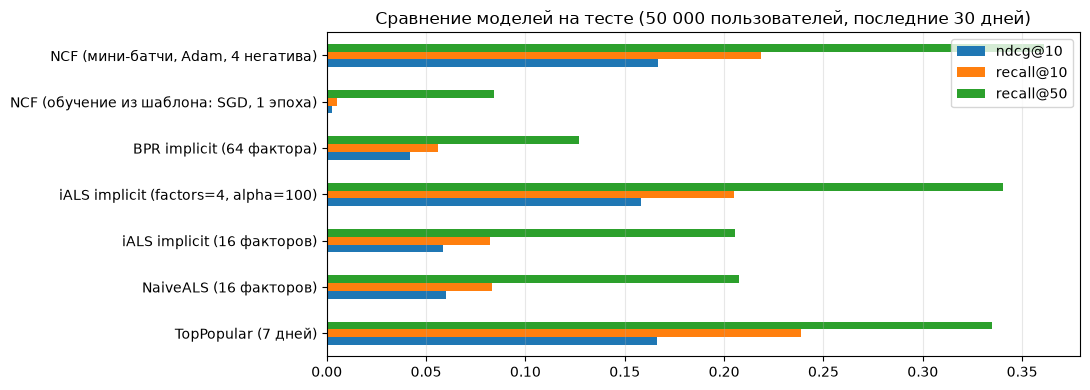

In [37]:
fig, ax = plt.subplots(figsize=(11, 4))
summary[['ndcg@10', 'recall@10', 'recall@50']].plot.barh(ax=ax)
ax.set_title('Сравнение моделей на тесте (50 000 пользователей, последние 30 дней)'); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

### Выводы

| модель | NDCG@10 | Recall@10 | NDCG@50 | Recall@50 |
|---|---|---|---|---|
| TopPopular за 7 дней | 0.166 | **0.239** | 0.192 | 0.335 |
| NaiveALS, 16 факторов | 0.060 | 0.083 | 0.095 | 0.208 |
| iALS (implicit), 16 факторов, alpha = 1 | 0.058 | 0.082 | 0.093 | 0.205 |
| iALS (implicit), 4 фактора, alpha = 100 | 0.158 | 0.205 | 0.196 | 0.340 |
| BPR (implicit), 64 фактора | 0.042 | 0.056 | 0.062 | 0.127 |
| NCF, обучение из шаблона | 0.002 | 0.005 | 0.024 | 0.084 |
| **NCF, мини-батчи + Adam** | **0.167** | 0.219 | **0.207** | **0.361** |

* **Популярность — очень сильный бейзлайн на KION.** Спрос сконцентрирован на свежих премьерах, и «популярное за последнюю неделю без просмотренного» сложно обойти по верху выдачи (Recall@10).
* **NaiveALS ≈ iALS с alpha = 1.**
  * В implicit доверие наблюдаемой пары c = alpha · r = 1, то есть (c − 1) = 0. Все пары, наблюдаемые и ненаблюдаемые, получают одинаковый вес 1, и iALS решает ту же задачу, что явный ALS по всей матрице «нули = не смотрел». Поэтому метрики почти равны.
  * В NaiveALS MSE по ненулевым быстро выходит на плато (≈ 0.745): модель с 16 факторами в основном восстанавливает нули.
* **У iALS решают гиперпараметры.** Чем меньше факторов и больше alpha, тем лучше. Качество монотонно падает с ростом числа факторов: при alpha = 40 NDCG@10 = 0.156 / 0.144 / 0.133 / 0.117 / 0.102 / 0.070 для 4 / 8 / 16 / 32 / 64 / 128 факторов. Лучшая конфигурация — 4 фактора и alpha = 100: Recall@50 = 0.340 и NDCG@50 = 0.196, это немного выше TopPopular, но NDCG@10 ниже (0.158). При 4 факторах модель фактически выучивает популярность с минимальной персонализацией. Сетка подбиралась по тестовым метрикам (отдельной валидации в шаблоне нет), так что это оптимистичная оценка для iALS.
* **BPR** без подбора learning rate и регуляризации оказался слабым.
* **NCF.** Вариант из шаблона не обучился (см. выше). Обученный мини-батчами — на уровне TopPopular по NDCG@10 (0.167 против 0.166), лучше всех по NDCG@50 и Recall@50 (0.361 против 0.335 у TopPopular), но уступает популярному по Recall@10.
* **Динамика обучения NCF.** Train loss падает с 0.34 до 0.13, а качество на контрольных 5 000 тестовых пользователей после 3–4-й эпохи почти не растёт (NDCG@10 ≈ 0.163–0.168): дальше модель уже запоминает трейн. Эти пользователи использовались только для отображения динамики — число эпох (6) было зафиксировано заранее и по ним не выбиралось.
* **Про метрику из шаблона.** `ndcg_metric` строит релевантность по порядку `gt_items`, а не по позициям рекомендаций, поэтому не чувствительна к порядку выдачи. Выводы выше сделаны по стандартному `ndcg@k`.